# 07. Динамика индекса состава


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Сводный индекс считается по изделиям, которые **в этот день ещё в составе**: уже поступили и ещё не выбыли. Так видно, растёт ли качество действующего набора, а не архива.

| | |
|---|---|
| **Данные** | `data/lineage.csv`, `data/measurements.csv`, `data/inventory.csv` |
| **Цель** | Средний индекс состава по месяцам |
| **Результат** | График динамики и различие полного архива против текущего состава |


In [2]:
library(rrBLUP)
library(AGHmatrix)
library(Matrix)
library(pedigreeTools)
library(dplyr)
library(ggplot2)
library(tidyr)
library(stringr)
library(e1071)
library(knitr)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Attaching package: ‘tidyr’



The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack



In [3]:
z_score_filter <- function(pipeline, threshold) {
  z <- abs((pipeline$trait - mean(pipeline$trait, na.rm = TRUE)) / sd(pipeline$trait, na.rm = TRUE))
  pipeline %>% filter(!(z > threshold))
}

bending <- function(matrix, epsilon) {
  e <- eigen(matrix)
  e$values[e$values < epsilon] <- epsilon
  out <- e$vectors %*% diag(e$values) %*% t(e$vectors)
  rownames(out) <- rownames(matrix)
  colnames(out) <- colnames(matrix)
  out
}

scale_g_to_a <- function(A_matrix, G_matrix) {
  common <- intersect(rownames(G_matrix), rownames(A_matrix))
  G_matrix <- G_matrix[common, common, drop = FALSE]
  A22 <- A_matrix[common, common, drop = FALSE]
  G_matrix * (sum(diag(A22)) / sum(diag(G_matrix)))
}

prepare_ids <- function(lineage, measurements, markers = NULL) {
  ids <- unique(c(measurements$item_id, lineage$item_id, lineage$parent_a, lineage$parent_b))
  if (!is.null(markers)) ids <- unique(c(ids, markers$item_id))
  ids <- ids[ids != 0]
  levels <- as.character(sort(unique(ids)))
  recode <- function(x) as.integer(factor(as.character(x), levels = levels))
  lineage <- lineage %>%
    mutate(
      item_id = recode(item_id),
      parent_a = ifelse(parent_a == 0, 0L, recode(parent_a)),
      parent_b = ifelse(parent_b == 0, 0L, recode(parent_b))
    )
  measurements <- measurements %>% mutate(item_id = recode(item_id))
  if (!is.null(markers)) {
    markers <- markers %>% mutate(item_id = recode(item_id))
  }
  list(lineage = lineage, measurements = measurements, markers = markers, levels = levels)
}

order_lineage <- function(lineage, keep_ids) {
  ped <- editPed(label = lineage$item_id, sire = lineage$parent_a, dam = lineage$parent_b)
  ped <- ped[, c("label", "sire", "dam")]
  names(ped) <- c("item_id", "parent_a", "parent_b")
  ped <- ped %>% filter(item_id %in% keep_ids)
  ped$parent_a[!(ped$parent_a %in% ped$item_id)] <- 0
  ped$parent_b[!(ped$parent_b %in% ped$item_id)] <- 0
  rownames(ped) <- ped$item_id
  ped
}


In [4]:
measurements <- read.csv("data/measurements.csv")
lineage <- read.csv("data/lineage.csv")
inventory <- read.csv("data/inventory.csv")
inventory$date_in <- as.Date(inventory$date_in)
inventory$date_out <- as.Date(inventory$date_out)
measurements <- drop_na(measurements)
prep <- prepare_ids(lineage, measurements)
lineage_bl <- order_lineage(prep$lineage, prep$measurements$item_id)
meas_bl <- prep$measurements %>%
  mutate(event_season = factor(event_season), event_year = factor(event_year))
A <- Amatrix(lineage_bl[, c("item_id", "parent_a", "parent_b")], ploidy = 2)
rownames(A) <- as.character(rownames(A))
meas_bl <- meas_bl[as.character(meas_bl$item_id) %in% rownames(A), ]
meas_bl <- meas_bl[order(match(as.character(meas_bl$item_id), rownames(A))), ]
X <- model.matrix(~ line_age + batch_mass + batch_no + event_season + event_year, data = meas_bl)
Z <- model.matrix(~ 0 + factor(item_id, levels = rownames(A)), data = meas_bl)
colnames(Z) <- rownames(A)
res <- mixed.solve(y = meas_bl$trait, X = X, Z = Z, K = A)
scores <- data.frame(
  item_id = as.integer(prep$levels[as.integer(names(res$u))]),
  estimate = as.numeric(res$u)
) %>%
  left_join(inventory, by = "item_id")
head(scores)


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 0.0001166667  minutes 


  item_id    estimate    date_in   date_out
1       1  0.06184838 2022-09-27       <NA>
2       2  0.22996209 2022-09-21       <NA>
3       3  0.10433512 2024-05-11 2025-02-26
4       4  0.26988782 2023-01-08       <NA>
5       5 -0.35201347 2023-01-16 2023-06-24
6       6  0.00445076 2022-05-02 2022-09-02


# 1. Состав на дату


In [5]:
items_on_date <- function(day) {
  scores %>%
    filter(date_in <= day, is.na(date_out) | date_out >= day)
}
months <- seq.Date(as.Date("2022-03-01"), as.Date("2024-09-01"), by = "month")
dynamic <- data.frame(
  date = months,
  mean_index = sapply(months, function(d) mean(items_on_date(d)$estimate, na.rm = TRUE)),
  n_items = sapply(months, function(d) nrow(items_on_date(d)))
)
head(dynamic)


        date    mean_index n_items
1 2022-03-01  0.0353820156      12
2 2022-04-01  0.0115724193      20
3 2022-05-01 -0.0009738217      20
4 2022-06-01  0.0008341026      23
5 2022-07-01  0.0002504205      25
6 2022-08-01 -0.0043300103      26


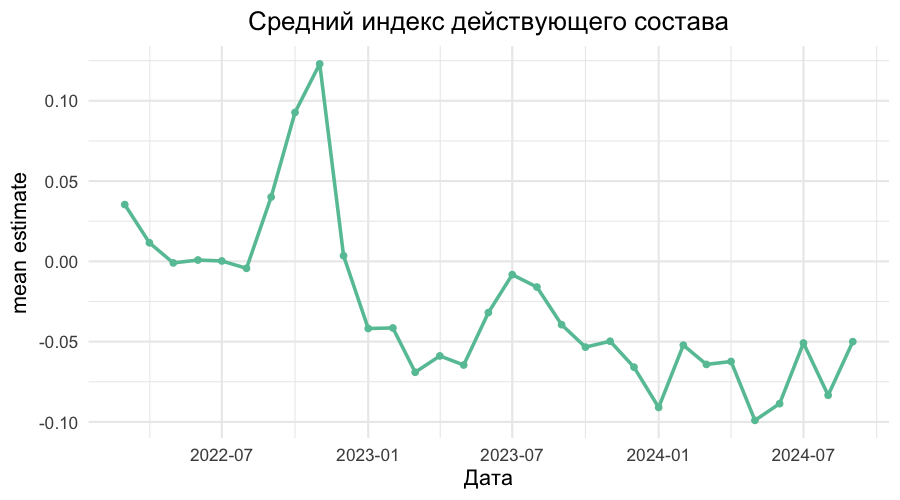

In [6]:
ggplot(dynamic, aes(x = date, y = mean_index)) +
  geom_line(color = "#66C2A5", linewidth = 1) +
  geom_point(color = "#66C2A5") +
  labs(title = "Средний индекс действующего состава", x = "Дата", y = "mean estimate") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


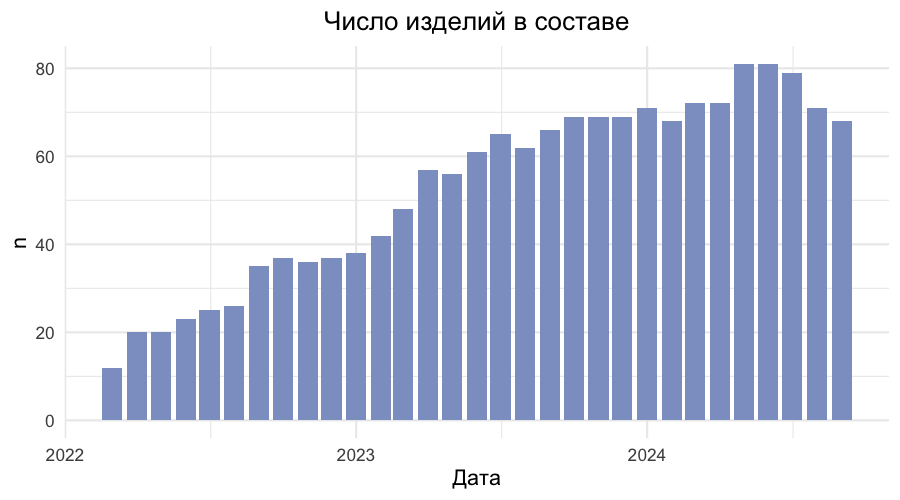

In [7]:
ggplot(dynamic, aes(x = date, y = n_items)) +
  geom_col(fill = "#8DA0CB") +
  labs(title = "Число изделий в составе", x = "Дата", y = "n") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 2. Архив против текущего состава


In [8]:
today <- as.Date("2024-09-01")
current <- items_on_date(today)
archive_mean <- mean(scores$estimate, na.rm = TRUE)
current_mean <- mean(current$estimate, na.rm = TRUE)
data.frame(
  set = c("Архив всех изделий", "Состав на дату"),
  n = c(nrow(scores), nrow(current)),
  mean_estimate = c(archive_mean, current_mean)
)


                 set   n mean_estimate
1 Архив всех изделий 200   -0.02950885
2     Состав на дату  68   -0.05000985


# Заключение

Индекс «всех когда-либо учтённых изделий» смешивает выбывшие позиции с текущими. Для решения «что держать в составе завтра» нужен срез по `date_in` / `date_out`. Если кривая среднего индекса идёт вверх при стабильной численности — качество действующего набора растёт.
